# Tabelas de categorias

Relaciona as categorias de produto com os pedidos e as avaliações, a partir da camada processed. Gera duas tabelas:

| Tabela | Uma linha por | Uso |
|---|---|---|
| `order_items_category` | item de pedido | Receita, volume e participação por categoria |
| `category_reviews` | categoria | Avaliação média e atraso por categoria |

## Bibliotecas

In [1]:
%run ../../src/librarys.ipynb

## Carga da camada processed

Lê as tabelas geradas no notebook de normalização. As colunas de data precisam ser indicadas em `parse_dates`, porque o CSV não guarda o tipo da coluna.

In [2]:
orders_enriched = pd.read_csv(
    "../../data/processed/orders_enriched.csv",
    parse_dates=["order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date"],
)
order_items = pd.read_csv("../../data/processed/order_items.csv")
products = pd.read_csv("../../data/processed/products.csv")
category_translation = pd.read_csv("../../data/processed/category_translation.csv")

## 1. Produtos com categoria

Junta produtos com a tradução da categoria. Dois ajustes:
- produtos **sem categoria** recebem `SEM CATEGORIA`, para não sumirem nos agrupamentos;
- as 2 categorias **sem tradução** recebem o próprio nome em português.

In [3]:
products_category = products.merge(category_translation, on="product_category_name", how="left")

products_category["product_category_name"] = products_category["product_category_name"].fillna("SEM CATEGORIA")
products_category["product_category_name_english"] = products_category["product_category_name_english"].fillna(
    products_category["product_category_name"]
)

products_category[["product_id", "product_category_name", "product_category_name_english"]].head(10)

,product_id,product_category_name,product_category_name_english
0,1e9e8ef04dbcff4541ed26657ea517e5,PERFUMARIA,PERFUMERY
1,3aa071139cb16b67ca9e5dea641aaa2f,ARTES,ART
2,96bd76ec8810374ed1b65e291975717f,ESPORTE_LAZER,SPORTS_LEISURE
3,cef67bcfe19066a932b7673e239eb23d,BEBES,BABY
4,9dc1a7de274444849c219cff195d0b71,UTILIDADES_DOMESTICAS,HOUSEWARES
5,41d3672d4792049fa1779bb35283ed13,INSTRUMENTOS_MUSICAIS,MUSICAL_INSTRUMENTS
6,732bd381ad09e530fe0a5f457d81becb,COOL_STUFF,COOL_STUFF
7,2548af3e6e77a690cf3eb6368e9ab61e,MOVEIS_DECORACAO,FURNITURE_DECOR
8,37cc742be07708b53a98702e77a21a02,ELETRODOMESTICOS,HOME_APPLIANCES
9,8c92109888e8cdf9d66dc7e463025574,BRINQUEDOS,TOYS


In [4]:
products_category[["product_category_name", "product_category_name_english"]].isna().sum()

product_category_name            0
product_category_name_english    0
dtype: int64

## 2. Categorias com pedidos

Junta cada item de pedido com a categoria do produto e com as informações do pedido (status, data, UF, avaliação e atraso). A tabela fica no nível de **item**, porque um mesmo pedido pode ter produtos de categorias diferentes.

O número de linhas deve continuar igual ao de `order_items`: se aumentar, algum join duplicou linhas.

In [5]:
order_items_category = order_items.merge(
    products_category[["product_id", "product_category_name", "product_category_name_english"]],
    on="product_id",
    how="left",
)
order_items_category = order_items_category.merge(
    orders_enriched[["order_id", "order_status", "order_purchase_timestamp", "customer_state", "review_score", "is_late"]],
    on="order_id",
    how="left",
)

print("Itens antes:", len(order_items))
print("Itens depois:", len(order_items_category))

Itens antes: 112650
Itens depois: 112650


In [6]:
order_items_category.head(10)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_category_name_english,order_status,order_purchase_timestamp,customer_state,review_score,is_late
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,COOL_STUFF,COOL_STUFF,DELIVERED,2017-09-13 08:59:02,RJ,5.0,0.0
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,PET_SHOP,PET_SHOP,DELIVERED,2017-04-26 10:53:06,SP,4.0,0.0
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,MOVEIS_DECORACAO,FURNITURE_DECOR,DELIVERED,2018-01-14 14:33:31,MG,5.0,0.0
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,PERFUMARIA,PERFUMERY,DELIVERED,2018-08-08 10:00:35,SP,4.0,0.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,FERRAMENTAS_JARDIM,GARDEN_TOOLS,DELIVERED,2017-02-04 13:57:51,SP,5.0,0.0
5,00048cc3ae777c65dbb7d2a0634bc1ea,1,ef92defde845ab8450f9d70c526ef70f,6426d21aca402a131fc0a5d0960a3c90,2017-05-23 03:55:27,21.90,12.69,UTILIDADES_DOMESTICAS,HOUSEWARES,DELIVERED,2017-05-15 21:42:34,MG,4.0,0.0
6,00054e8431b9d7675808bcb819fb4a32,1,8d4f2bb7e93e6710a28f34fa83ee7d28,7040e82f899a04d1b434b795a43b4617,2017-12-14 12:10:31,19.90,11.85,TELEFONIA,TELEPHONY,DELIVERED,2017-12-10 11:53:48,SP,4.0,0.0
7,000576fe39319847cbb9d288c5617fa6,1,557d850972a7d6f792fd18ae1400d9b6,5996cddab893a4652a15592fb58ab8db,2018-07-10 12:30:45,810.00,70.75,FERRAMENTAS_JARDIM,GARDEN_TOOLS,DELIVERED,2018-07-04 12:08:27,SP,5.0,0.0
8,0005a1a1728c9d785b8e2b08b904576c,1,310ae3c140ff94b03219ad0adc3c778f,a416b6a846a11724393025641d4edd5e,2018-03-26 18:31:29,145.95,11.65,BELEZA_SAUDE,HEALTH_BEAUTY,DELIVERED,2018-03-19 18:40:33,SP,1.0,0.0
9,0005f50442cb953dcd1d21e1fb923495,1,4535b0e1091c278dfd193e5a1d63b39f,ba143b05f0110f0dc71ad71b4466ce92,2018-07-06 14:10:56,53.99,11.40,LIVROS_TECNICOS,BOOKS_TECHNICAL,DELIVERED,2018-07-02 13:59:39,SP,4.0,0.0


Categorias com mais itens vendidos.

In [7]:
order_items_category["product_category_name"].value_counts().head(10)

product_category_name
CAMA_MESA_BANHO           11115
BELEZA_SAUDE               9670
ESPORTE_LAZER              8641
MOVEIS_DECORACAO           8334
INFORMATICA_ACESSORIOS     7827
UTILIDADES_DOMESTICAS      6964
RELOGIOS_PRESENTES         5991
TELEFONIA                  4545
FERRAMENTAS_JARDIM         4347
AUTOMOTIVO                 4235
Name: count, dtype: int64

## 3. Avaliação por categoria

Para cada categoria: quantidade de pedidos, avaliação média, percentual de pedidos atrasados e receita.

Antes de calcular a avaliação e o atraso, ficamos com **um registro por pedido e categoria**. Sem isso, um pedido com 5 itens iguais teria a avaliação contada 5 vezes, pesando mais na média do que um pedido com 1 item.

In [8]:
pedido_categoria = order_items_category.drop_duplicates(["order_id", "product_category_name"])

category_reviews = pedido_categoria.groupby(["product_category_name", "product_category_name_english"]).agg(
    pedidos=("order_id", "nunique"),
    review_medio=("review_score", "mean"),
    pct_atraso=("is_late", "mean"),
).reset_index()

receita = order_items_category.groupby("product_category_name")["price"].sum().reset_index(name="receita")
category_reviews = category_reviews.merge(receita, on="product_category_name", how="left")

category_reviews["pct_atraso"] = category_reviews["pct_atraso"] * 100
category_reviews = category_reviews.sort_values("pedidos", ascending=False)

category_reviews.head(10)

,product_category_name,product_category_name_english,pedidos,review_medio,pct_atraso,receita
13,CAMA_MESA_BANHO,BED_BATH_TABLE,9417,3.970740,7.430975,1036988.68
11,BELEZA_SAUDE,HEALTH_BEAUTY,8836,4.181203,7.515320,1258681.34
32,ESPORTE_LAZER,SPORTS_LEISURE,7720,4.167362,6.573705,988048.97
44,INFORMATICA_ACESSORIOS,COMPUTERS_ACCESSORIES,6689,4.026245,6.386889,911954.32
54,MOVEIS_DECORACAO,FURNITURE_DECOR,6449,4.009691,7.119074,729762.49
73,UTILIDADES_DOMESTICAS,HOUSEWARES,5884,4.142221,5.363051,632248.66
66,RELOGIOS_PRESENTES,WATCHES_GIFTS,5624,4.065459,7.391225,1205005.68
71,TELEFONIA,TELEPHONY,4199,4.003119,7.109699,323667.53
8,AUTOMOTIVO,AUTO,3897,4.090147,7.298504,592720.11
12,BRINQUEDOS,TOYS,3886,4.189333,6.388013,483946.60


Categorias com pior avaliação média, considerando apenas as com pelo menos 100 pedidos (categorias muito pequenas têm médias instáveis).

In [9]:
category_reviews[category_reviews["pedidos"] >= 100].sort_values("review_medio").head(10)

,product_category_name,product_category_name_english,pedidos,review_medio,pct_atraso,receita
55,MOVEIS_ESCRITORIO,OFFICE_FURNITURE,1273,3.616390,8.054226,273960.70
38,FASHION_ROUPA_MASCULINA,FASHION_MALE_CLOTHING,112,3.702703,4.716981,10797.82
7,AUDIO,AUDIO,350,3.834294,11.781609,50688.50
25,CONSTRUCAO_FERRAMENTAS_SEGURANCA,CONSTRUCTION_TOOLS_SAFETY,167,3.849398,2.515723,40544.52
14,CASA_CONFORTO,HOME_CONFORT,397,3.863291,9.438776,58572.04
72,TELEFONIA_FIXA,FIXED_TELEPHONY,217,3.901869,4.716981,59583.00
68,SEM CATEGORIA,SEM CATEGORIA,1451,3.912787,7.255747,179535.28
39,FASHION_UNDERWEAR_E_MODA_PRAIA,FASHION_UNDERWEAR_BEACH,121,3.933333,9.401709,9541.55
16,CASA_CONSTRUCAO,HOME_CONSTRUCTION,490,3.967146,6.004141,83088.12
13,CAMA_MESA_BANHO,BED_BATH_TABLE,9417,3.970740,7.430975,1036988.68


Avaliação média das 15 categorias com mais pedidos.

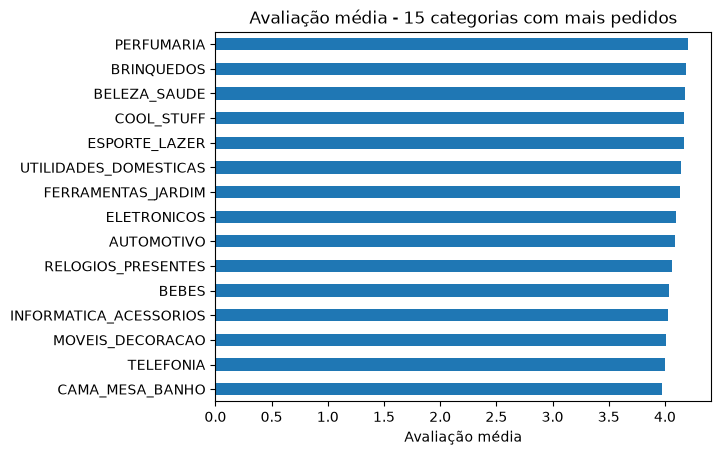

In [10]:
top15 = category_reviews.head(15).sort_values("review_medio")

top15.plot(kind="barh", x="product_category_name", y="review_medio", legend=False, title="Avaliação média - 15 categorias com mais pedidos")
plt.xlabel("Avaliação média")
plt.ylabel("")
plt.show()

## 4. Salvar

Grava as duas tabelas na camada processed.

In [11]:
order_items_category.to_csv("../../data/processed/order_items_category.csv", index=False)
category_reviews.to_csv("../../data/processed/category_reviews.csv", index=False)